In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.gridspec import GridSpec
%config InlineBackend.figure_format='retina'
sns.set_style('ticks')

# Supplemental Figure 1

In [2]:
instrument_operator = pd.read_csv("instrument_operator.csv")
raw_spectra = pd.read_csv("raw_spectra.csv")
convolved_spectra = pd.read_csv("control_spectra.csv")

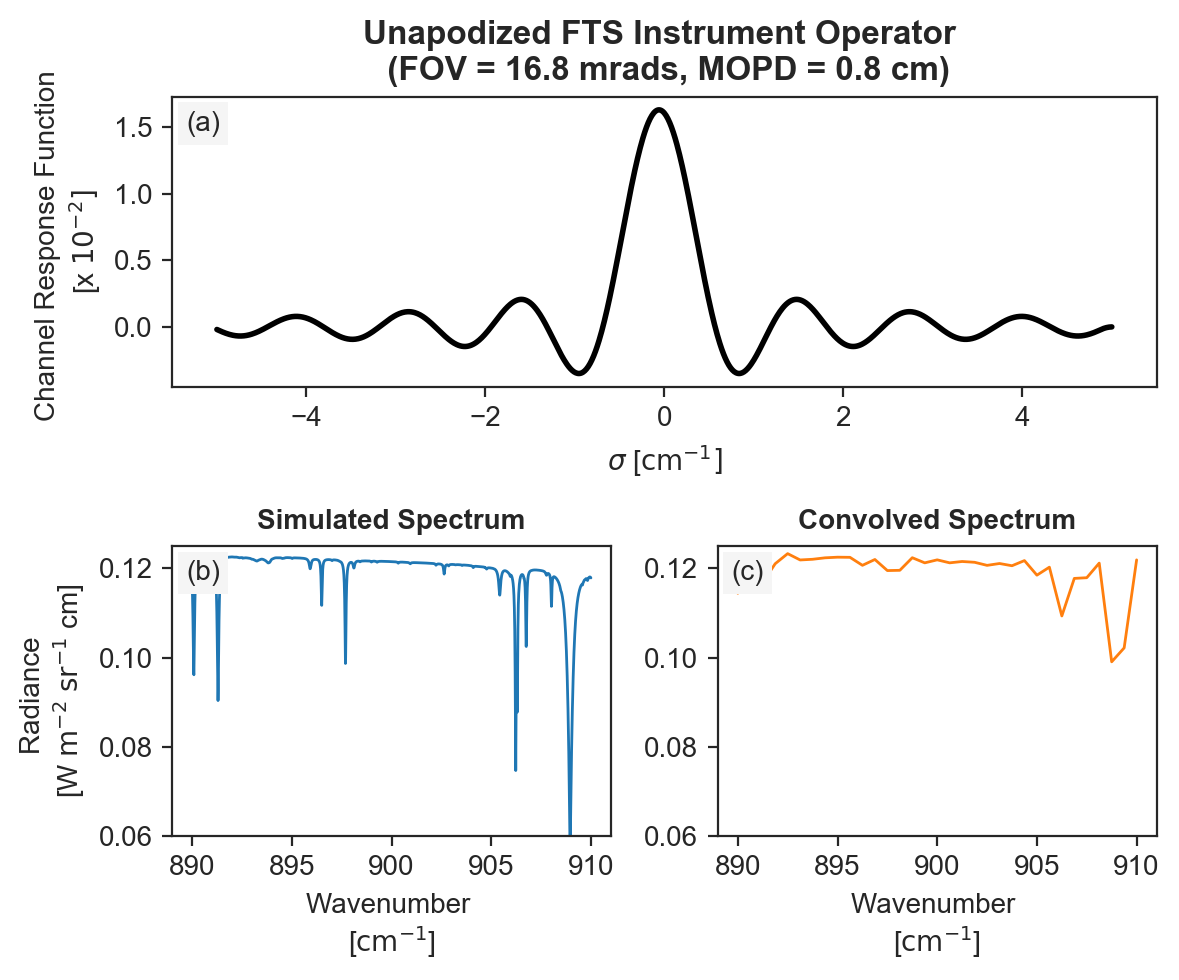

In [9]:
fig = plt.figure(figsize = (6,5), tight_layout = True)

gs = GridSpec(2,2)
ax = fig.add_subplot(gs[0,:])
ax.plot(instrument_operator.wavenumbers, instrument_operator.instrument_kernel / 0.01, lw = 2, color = 'black')

ax.annotate("(a)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_title("Unapodized FTS Instrument Operator \n (FOV = 16.8 mrads, MOPD = 0.8 cm)", weight = "bold")
ax.set_ylabel("Channel Response Function \n[x $10^{-2}]$");
ax.set_xlabel("$\\sigma$ [$\\mathrm{cm^{-1}}]$");

ax = fig.add_subplot(gs[1,0])
ax.plot(raw_spectra.wavenumbers, raw_spectra.co2_o2_h2o_isopx5, lw = 1, color = 'tab:blue')
ax.annotate("(b)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_ylim([0.06, 0.125])
ax.set_ylabel("Radiance \n[W $\\mathrm{m^{-2}}$ $\\mathrm{sr^{-1}}$ cm]")
ax.set_xlabel("Wavenumber \n[$\\mathrm{cm^{-1}}$]")
ax.set_title("Simulated Spectrum", weight = "bold", fontsize = 10)

ax = fig.add_subplot(gs[1,1])
ax.plot(convolved_spectra.wavenumbers, convolved_spectra.co2_o2_h2o_isopx5, lw = 1, color = 'tab:orange')
ax.annotate("(c)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_ylim([0.06, 0.125])
ax.set_xlabel("Wavenumber \n[$\\mathrm{cm^{-1}}$]")
ax.set_title("Convolved Spectrum", weight = "bold", fontsize = 10)

plt.subplots_adjust(wspace = 0.3)
fig.savefig("figs03.png", dpi = 300)

# Supplemental Figure 2

In [8]:
simulated = pd.read_csv("simulated_cross_sections_to_compare.csv")
experimental = pd.read_csv("experimental_cross_sections_to_compare.csv")

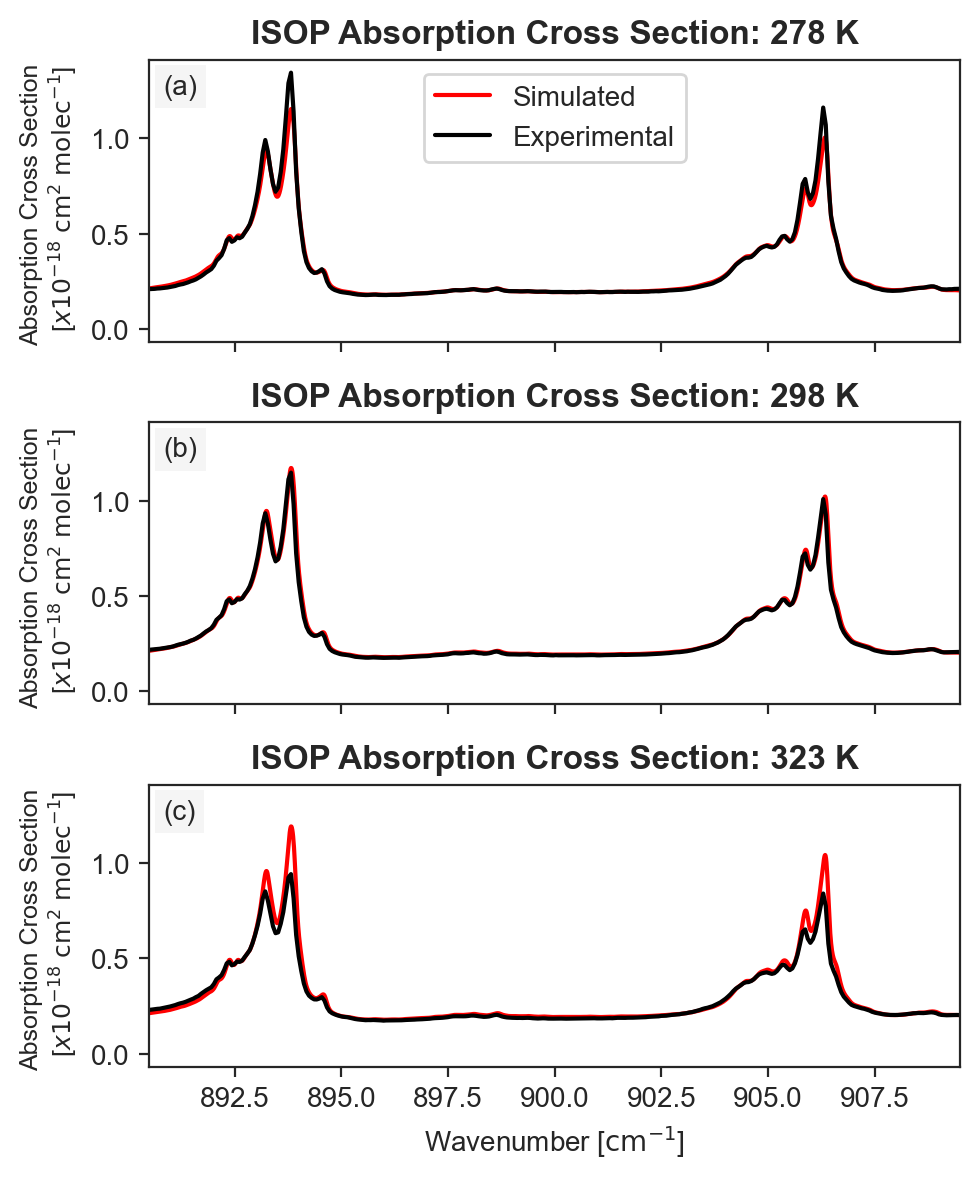

In [10]:
fig, (ax, ax2, ax3) = plt.subplots(3,1, tight_layout = True, sharex = True, sharey = True, figsize = (5,6))
scaling = 1e-18

ax.plot(simulated.wavenumber, simulated.absorption_cross_sections_278 / scaling, lw = 1.5, label = 'Simulated', color = 'red')
ax.plot(experimental.wavenumber, experimental.absorption_cross_sections_278 / scaling, lw = 1.5, label = 'Experimental', color = 'black')

ax.legend()
ax.set_xlim([890.5, 909.5])
ax.set_title("ISOP Absorption Cross Section: 278 K", weight = "bold")
ax.annotate("(a)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))

ax2.plot(simulated.wavenumber, simulated.absorption_cross_sections_298 / scaling, lw = 1.5, color = 'red')
ax2.plot(experimental.wavenumber, experimental.absorption_cross_sections_298 / scaling, lw = 1.5, label = 'Experimental', color = 'black')
ax2.set_title("ISOP Absorption Cross Section: 298 K", weight = "bold")
ax2.annotate("(b)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))

ax3.plot(simulated.wavenumber, simulated.absorption_cross_sections_323 / scaling, lw = 1.5, color = 'red')
ax3.plot(experimental.wavenumber, experimental.absorption_cross_sections_323 / scaling, lw = 1.5, label = 'Experimental', color = 'black')
ax3.set_title("ISOP Absorption Cross Section: 323 K", weight = "bold")
ax3.annotate("(c)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))


ax3.set_xlabel("Wavenumber [$\\mathrm{cm^{-1}}$]")
ax.set_ylabel("Absorption Cross Section \n [$x 10^{-18}$ $\\mathrm{cm^{2}}$ $\\mathrm{molec^{-1}}$]", fontsize = 9)
ax2.set_ylabel("Absorption Cross Section \n [$x 10^{-18}$ $\\mathrm{cm^{2}}$ $\\mathrm{molec^{-1}}$]", fontsize = 9)
ax3.set_ylabel("Absorption Cross Section \n [$x 10^{-18}$ $\\mathrm{cm^{2}}$ $\\mathrm{molec^{-1}}$]", fontsize = 9)
fig.savefig("figs01.png", dpi = 300)


# Supplemental Figure 3

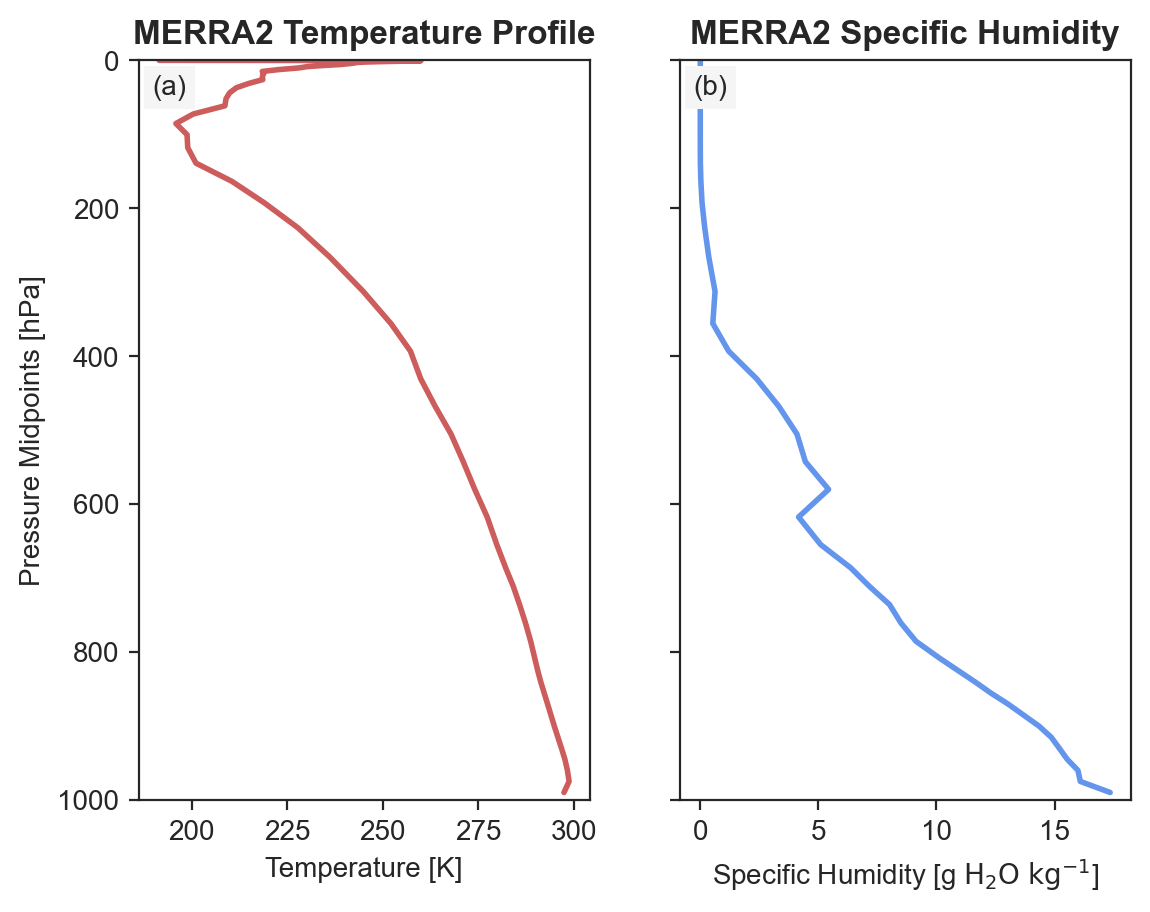

In [13]:
meteorology = pd.read_csv("meteorology.csv")

fig, (ax, ax2) = plt.subplots(1,2, sharey= True)
ax.set_ylabel("Pressure Midpoints [hPa]")
ax.set_xlabel("Temperature [K]")
ax2.set_xlabel("Specific Humidity [g $\\mathrm{H_2O}$ $\\mathrm{kg^{-1}}$]")
ax2.annotate("(b)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))

ax.plot(meteorology.temperatures, meteorology.pressures_midpoints, lw = 2, color = 'indianred')
ax2.plot(meteorology.specific_humidity, meteorology.pressures_midpoints, lw = 2, color = 'cornflowerblue')
ax.set_ylim([0, 1000])
ax.set_title("MERRA2 Temperature Profile", weight = "bold")
ax2.set_title("MERRA2 Specific Humidity", weight = "bold")
ax.annotate("(a)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))

ax.invert_yaxis()
fig.savefig("figs02.png", dpi = 300)


# Paper Figure

In [14]:
control = pd.read_csv("control_spectra.csv")
clouds = pd.read_csv("cloud_aerosols.csv")
water = pd.read_csv("water_sensitivity_spectra.csv")
vertical_profiles = pd.read_csv("vertical_profile_spectra.csv")
isoprene_profiles = pd.read_csv("isoprene_profiles.csv")

In [15]:
p = meteorology.pressures_midpoints

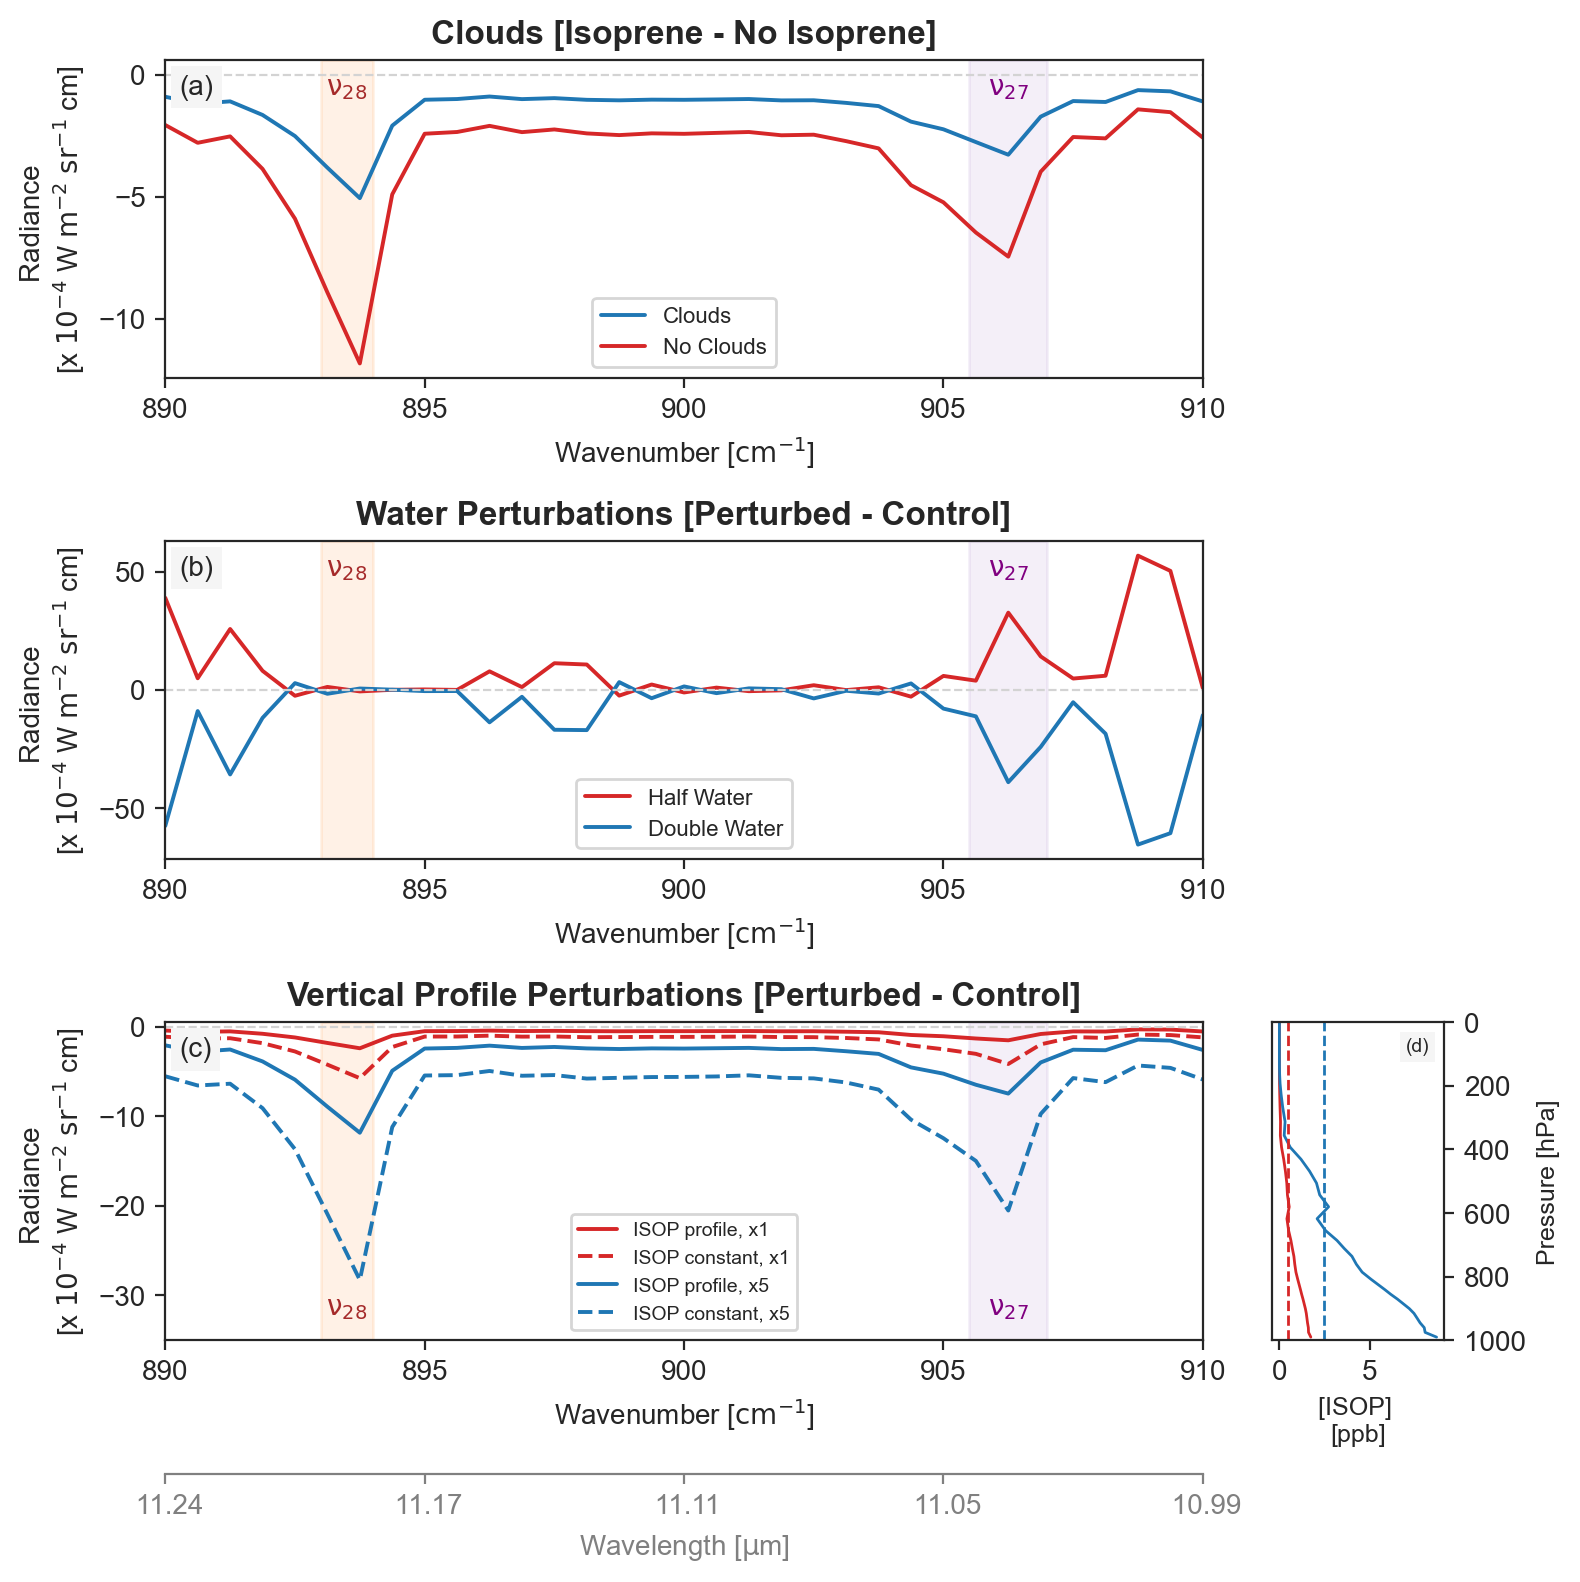

In [22]:
fig = plt.figure(figsize = (8,8), tight_layout = True)
scaling = 0.0001

gs = GridSpec(3,2, width_ratios=[6, 1])
ax = fig.add_subplot(gs[0,0])

ax.plot(clouds.wavenumbers, (clouds.isop_aer - clouds.no_isop_aer) / scaling, lw = 1.4, color = 'tab:blue', label = "Clouds")
ax.plot(clouds.wavenumbers, (clouds.isop_no_aer - clouds.no_isop_no_aer) / scaling, lw = 1.4, color = 'tab:red', label = "No Clouds")

ax.axhline(0, ls = 'dashed', color = 'lightgray', lw = 0.8)
ax.legend(fontsize = 8)
ax.annotate("(a)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_title("Clouds [Isoprene - No Isoprene]", weight = "bold")
ax.set_ylabel("Radiance \n[x $10^{-4}$ W $\\mathrm{m^{-2}}$ $\\mathrm{sr^{-1}}$ cm]")
ax.set_xlabel("Wavenumber [$\\mathrm{cm^{-1}}$]")
ax.set_xlim([890, 910])
ax.set_xticks(np.arange(890, 911, 5))

ax.text(0.175, 0.91, "$\\mathrm{\\nu_{28}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'brown', weight = 'bold')
ax.text(0.813, 0.91, "$\\mathrm{\\nu_{27}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'purple', weight = 'bold')
ax.axvspan(893, 894, alpha = 0.1, color = 'tab:orange')
ax.axvspan(905.5, 907, alpha = 0.1, color = 'tab:purple')

ax = fig.add_subplot(gs[1,0])
ax.plot(water.wavenumbers, (water.half_water - water.control) / scaling, lw = 1.4, color = 'tab:red', label = "Half Water")
ax.plot(water.wavenumbers, (water.double_water - water.control) / scaling, lw = 1.4, color = 'tab:blue', label = "Double Water")
ax.axhline(0, ls = 'dashed', color = 'lightgray', lw = 0.8)
ax.legend(fontsize = 8)
ax.annotate("(b)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_title("Water Perturbations [Perturbed - Control]", weight = "bold")
ax.set_ylabel("Radiance \n[x $10^{-4}$ W $\\mathrm{m^{-2}}$ $\\mathrm{sr^{-1}}$ cm]")
ax.set_xlabel("Wavenumber [$\\mathrm{cm^{-1}}$]")
ax.set_xlim([890, 910])
ax.set_xticks(np.arange(890, 911, 5))

ax.text(0.175, 0.91, "$\\mathrm{\\nu_{28}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'brown', weight = 'bold')
ax.text(0.813, 0.91, "$\\mathrm{\\nu_{27}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'purple', weight = 'bold')
ax.axvspan(893, 894, alpha = 0.1, color = 'tab:orange')
ax.axvspan(905.5, 907, alpha = 0.1, color = 'tab:purple')

ax = fig.add_subplot(gs[2,0])
ax.plot(vertical_profiles.wavenumbers, (vertical_profiles.isopx1 - vertical_profiles.co2_o2_h2o) / scaling, lw = 1.4, color = 'tab:red', label = "ISOP profile, x1")
ax.plot(vertical_profiles.wavenumbers, (vertical_profiles.isop_constantx1 - vertical_profiles.co2_o2_h2o) / scaling, lw = 1.4, color = 'tab:red', label = "ISOP constant, x1", ls = 'dashed')
ax.plot(vertical_profiles.wavenumbers, (vertical_profiles.isopx5 - vertical_profiles.co2_o2_h2o) / scaling, lw = 1.4, color = 'tab:blue', label = "ISOP profile, x5")
ax.plot(vertical_profiles.wavenumbers, (vertical_profiles.isop_constantx5 - vertical_profiles.co2_o2_h2o) / scaling, lw = 1.4, color = 'tab:blue', label = "ISOP constant, x5", ls = 'dashed')

ax.axhline(0, ls = 'dashed', color = 'lightgray', lw = 0.8)
ax.legend(fontsize = 7)
ax.annotate("(c)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_title("Vertical Profile Perturbations [Perturbed - Control]", weight = "bold")
ax.set_ylabel("Radiance \n[x $10^{-4}$ W $\\mathrm{m^{-2}}$ $\\mathrm{sr^{-1}}$ cm]")
ax.set_xlabel("Wavenumber [$\\mathrm{cm^{-1}}$]")
ax.set_xlim([890, 910])
ax.set_xticks(np.arange(890, 911, 5))

ax.text(0.175, 0.1, "$\\mathrm{\\nu_{28}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'brown', weight = 'bold')
ax.text(0.813, 0.1, "$\\mathrm{\\nu_{27}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'purple', weight = 'bold')
ax.axvspan(893, 894, alpha = 0.1, color = 'tab:orange')
ax.axvspan(905.5, 907, alpha = 0.1, color = 'tab:purple')

ax_wavelength = ax.secondary_xaxis(-50, transform=ax.transData)
ax_wavelength.set_xlabel("Wavelength [$\\mathrm{\\mu}$m]", color = 'gray')
ax_wavelength.set_xticks(ax.get_xticks())
ax_wavelength.set_xbound(ax.get_xbound())
ax_wavelength.set_xticklabels([f"{10**7 / x / 1e3 : .2f}" for x in ax.get_xticks()])
ax_wavelength.spines['bottom'].set_color('gray')
ax_wavelength.tick_params(axis='x', colors='gray')

ax_profile = fig.add_subplot(gs[2,1])
ax_profile.plot(isoprene_profiles.low_profile, p, color = 'tab:red', lw = 1)
ax_profile.plot(isoprene_profiles.high_profile, p, color = 'tab:blue', lw = 1)
ax_profile.axvline(0.49235111030987266, color = 'tab:red', ls = 'dashed', lw = 1)
ax_profile.axvline(2.4617555515493637, color = 'tab:blue', ls = 'dashed', lw = 1)
ax_profile.yaxis.tick_right()
ax_profile.yaxis.set_label_position("right")

ax_profile.set_xlabel("[ISOP] \n[ppb]", fontsize = 9)
ax_profile.set_ylabel("Pressure [hPa]", fontsize = 9)
ax_profile.annotate("(d)", xy=(1, 1), xycoords='axes fraction', xytext=(-2, -0.8), textcoords='offset fontsize', fontsize=7, verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=2.0))
ax_profile.set_ylim([1000, 0])

ax.set_ylim([-35, 0.5])
plt.subplots_adjust(wspace = 0, hspace = 0.8)
fig.savefig("fig06.png", dpi = 300)

In [215]:
experimental = pd.read_csv("experimental_cross_sections_to_compare.csv")

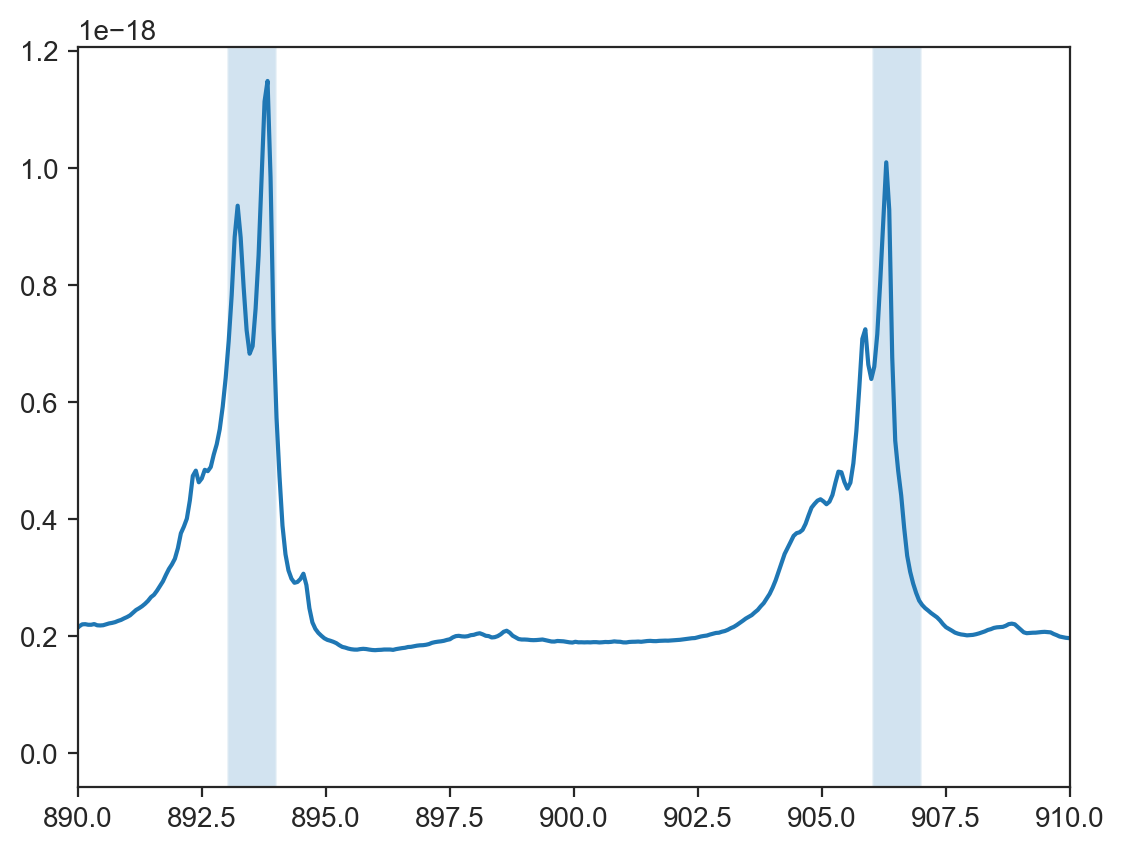

In [234]:
plt.plot(experimental.wavenumber, experimental.absorption_cross_sections_298)
plt.xlim([890,910])
plt.axvspan(893, 894, alpha = 0.2)
plt.axvspan(906, 907, alpha = 0.2)

# plt.ylim([0, 0.002e-18])

In [328]:
isoprene_profiles

,low_profile,high_profile
0,0.000281,0.001403
1,0.000342,0.001711
2,0.000380,0.001898
3,0.000410,0.002052
4,0.000417,0.002083
...,...,...
67,1.520111,7.600554
68,1.553785,7.768924
69,1.599006,7.995028
70,1.609077,8.045386


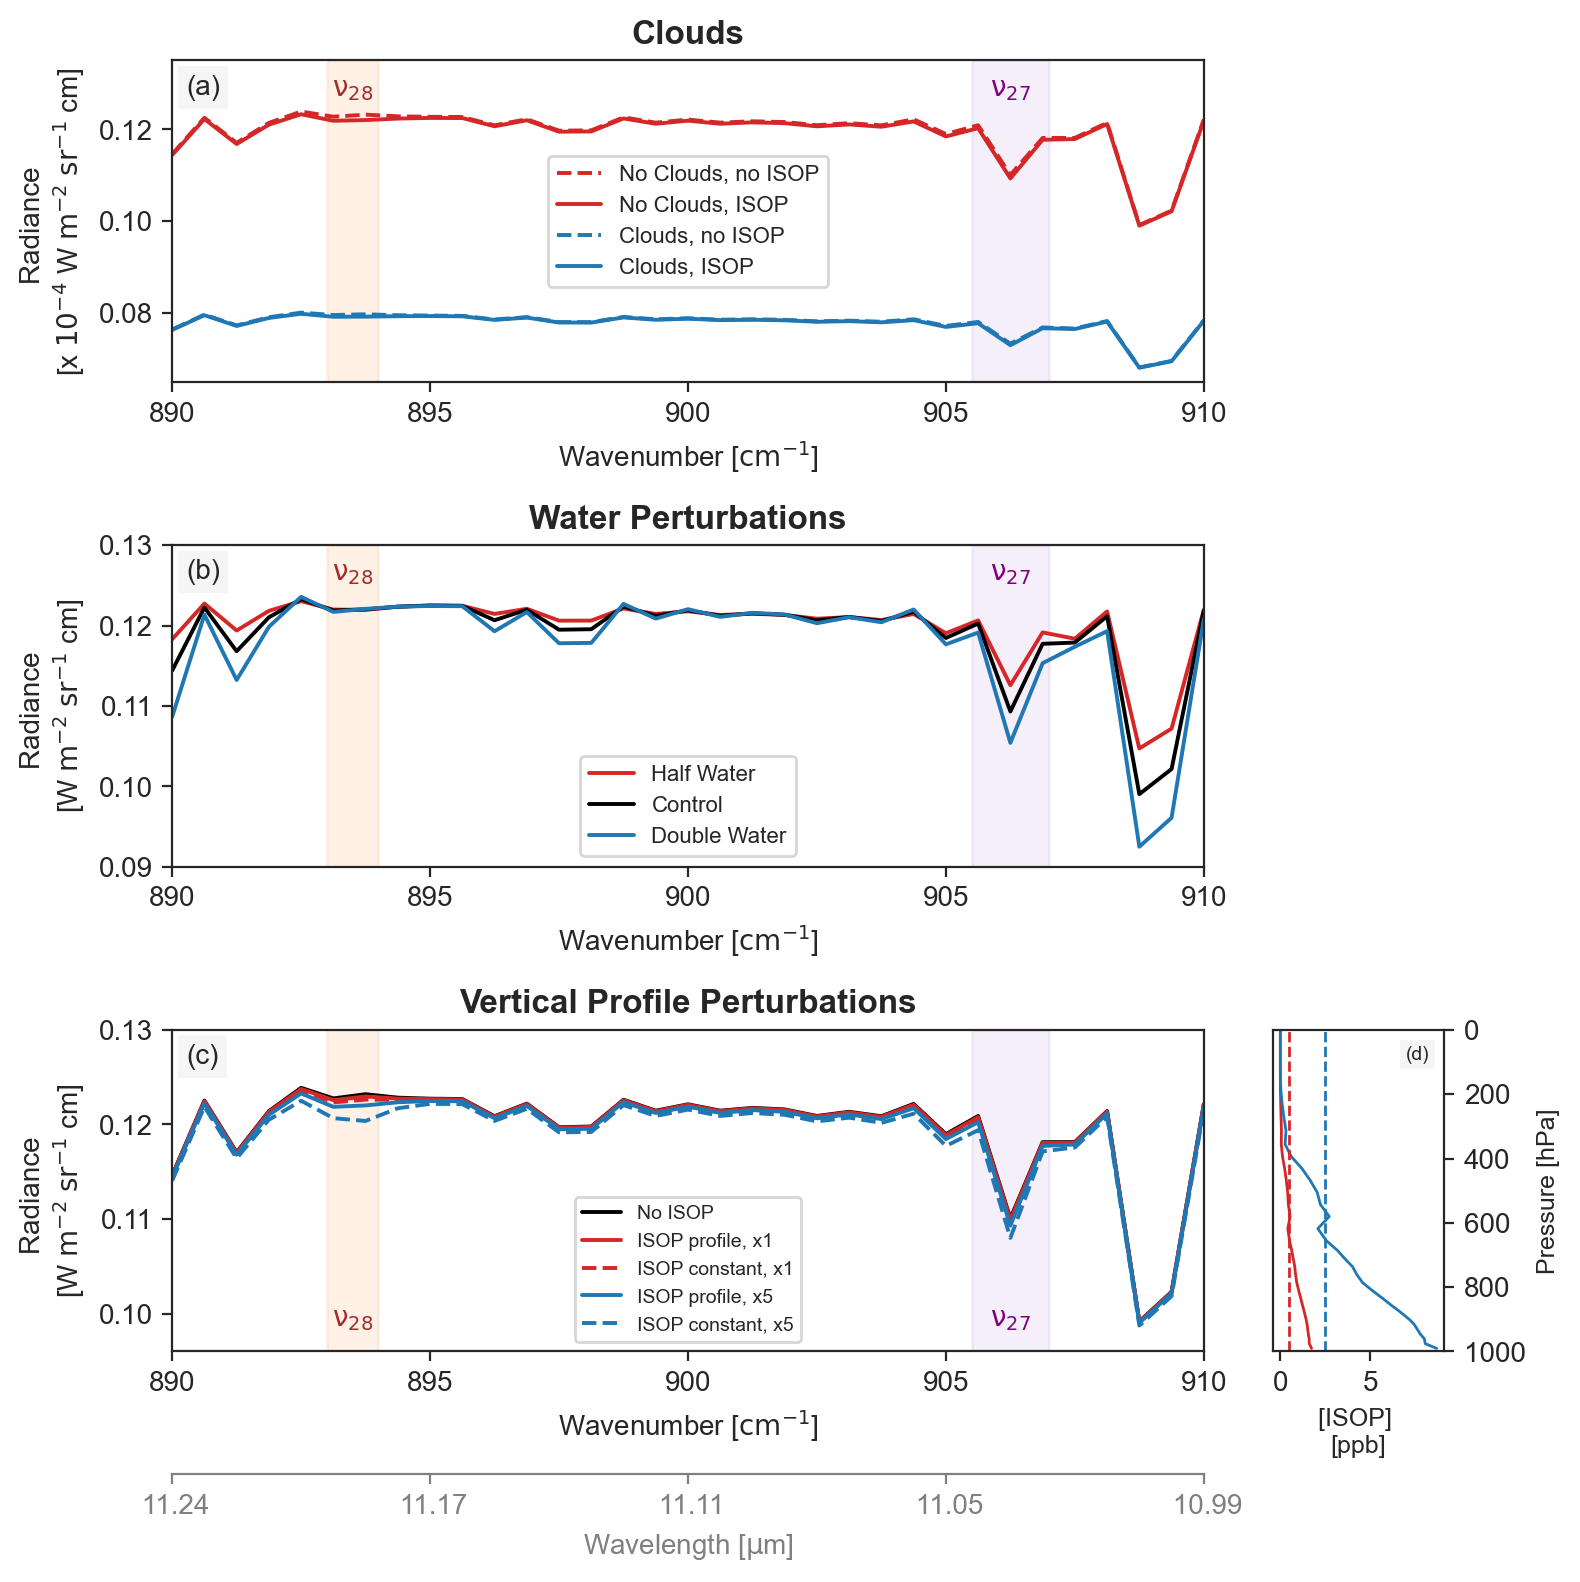

In [28]:
fig = plt.figure(figsize = (8,8), tight_layout = True)
scaling = 0.0001

gs = GridSpec(3,2, width_ratios=[6, 1])
ax = fig.add_subplot(gs[0,0])

ax.plot(clouds.wavenumbers, clouds.no_isop_no_aer, lw = 1.4, color = 'tab:red', ls = 'dashed', label = "No Clouds, no ISOP")
ax.plot(clouds.wavenumbers, clouds.isop_no_aer, lw = 1.4, color = 'tab:red',  label = "No Clouds, ISOP")
ax.plot(clouds.wavenumbers, clouds.no_isop_aer, lw = 1.4, color = 'tab:blue', ls = 'dashed', label = "Clouds, no ISOP")
ax.plot(clouds.wavenumbers, clouds.isop_aer, lw = 1.4, color = 'tab:blue', label = "Clouds, ISOP")
ax.set_ylim([0.065, 0.135])

ax.axhline(0, ls = 'dashed', color = 'lightgray', lw = 0.8)
ax.legend(fontsize = 8)
ax.annotate("(a)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_title("Clouds", weight = "bold")
ax.set_ylabel("Radiance \n[x $10^{-4}$ W $\\mathrm{m^{-2}}$ $\\mathrm{sr^{-1}}$ cm]")
ax.set_xlabel("Wavenumber [$\\mathrm{cm^{-1}}$]")
ax.set_xlim([890, 910])
ax.set_xticks(np.arange(890, 911, 5))

ax.text(0.175, 0.91, "$\\mathrm{\\nu_{28}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'brown', weight = 'bold')
ax.text(0.813, 0.91, "$\\mathrm{\\nu_{27}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'purple', weight = 'bold')
ax.axvspan(893, 894, alpha = 0.1, color = 'tab:orange')
ax.axvspan(905.5, 907, alpha = 0.1, color = 'tab:purple')

ax = fig.add_subplot(gs[1,0])
ax.plot(water.wavenumbers, water.half_water, lw = 1.4, color = 'tab:red', label = "Half Water")
ax.plot(water.wavenumbers, water.control, lw = 1.4, color = 'black', label = "Control")
ax.plot(water.wavenumbers, water.double_water, lw = 1.4, color = 'tab:blue', label = "Double Water")
ax.set_ylim([0.09, 0.13])
ax.axhline(0, ls = 'dashed', color = 'lightgray', lw = 0.8)
ax.legend(fontsize = 8)
ax.annotate("(b)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_title("Water Perturbations", weight = "bold")
ax.set_ylabel("Radiance \n[W $\\mathrm{m^{-2}}$ $\\mathrm{sr^{-1}}$ cm]")
ax.set_xlabel("Wavenumber [$\\mathrm{cm^{-1}}$]")
ax.set_xlim([890, 910])
ax.set_xticks(np.arange(890, 911, 5))

ax.text(0.175, 0.91, "$\\mathrm{\\nu_{28}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'brown', weight = 'bold')
ax.text(0.813, 0.91, "$\\mathrm{\\nu_{27}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'purple', weight = 'bold')
ax.axvspan(893, 894, alpha = 0.1, color = 'tab:orange')
ax.axvspan(905.5, 907, alpha = 0.1, color = 'tab:purple')

ax = fig.add_subplot(gs[2,0])
ax.plot(vertical_profiles.wavenumbers, vertical_profiles.co2_o2_h2o, lw = 1.4, color = 'black', label = "No ISOP")
ax.plot(vertical_profiles.wavenumbers, vertical_profiles.isopx1, lw = 1.4, color = 'tab:red', label = "ISOP profile, x1")
ax.plot(vertical_profiles.wavenumbers, vertical_profiles.isop_constantx1, lw = 1.4, color = 'tab:red', label = "ISOP constant, x1", ls = 'dashed')
ax.plot(vertical_profiles.wavenumbers, vertical_profiles.isopx5, lw = 1.4, color = 'tab:blue', label = "ISOP profile, x5")
ax.plot(vertical_profiles.wavenumbers, vertical_profiles.isop_constantx5, lw = 1.4, color = 'tab:blue', label = "ISOP constant, x5", ls = 'dashed')

ax.axhline(0, ls = 'dashed', color = 'lightgray', lw = 0.8)
ax.legend(fontsize = 7)
ax.annotate("(c)", xy=(0, 1), xycoords='axes fraction', xytext=(+0.5, -0.5), textcoords='offset fontsize', fontsize='medium', verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=3.0))
ax.set_title("Vertical Profile Perturbations", weight = "bold")
ax.set_ylabel("Radiance \n[W $\\mathrm{m^{-2}}$ $\\mathrm{sr^{-1}}$ cm]")
ax.set_xlabel("Wavenumber [$\\mathrm{cm^{-1}}$]")
ax.set_xlim([890, 910])
ax.set_xticks(np.arange(890, 911, 5))

ax.text(0.175, 0.1, "$\\mathrm{\\nu_{28}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'brown', weight = 'bold')
ax.text(0.813, 0.1, "$\\mathrm{\\nu_{27}}$", horizontalalignment='center', verticalalignment='center', transform=ax.transAxes, color = 'purple', weight = 'bold')
ax.axvspan(893, 894, alpha = 0.1, color = 'tab:orange')
ax.axvspan(905.5, 907, alpha = 0.1, color = 'tab:purple')

ax_wavelength = ax.secondary_xaxis(location = 0.083, transform=ax.transData)
ax_wavelength.set_xlabel("Wavelength [$\\mathrm{\\mu}$m]", color = 'gray')
ax_wavelength.set_xticks(ax.get_xticks())
ax_wavelength.set_xbound(ax.get_xbound())
ax_wavelength.set_xticklabels([f"{10**7 / x / 1e3 : .2f}" for x in ax.get_xticks()])
ax_wavelength.spines['bottom'].set_color('gray')
ax_wavelength.tick_params(axis='x', colors='gray')

ax_profile = fig.add_subplot(gs[2,1])
ax_profile.plot(isoprene_profiles.low_profile, p, color = 'tab:red', lw = 1)
ax_profile.plot(isoprene_profiles.high_profile, p, color = 'tab:blue', lw = 1)
ax_profile.axvline(0.49235111030987266, color = 'tab:red', ls = 'dashed', lw = 1)
ax_profile.axvline(2.4617555515493637, color = 'tab:blue', ls = 'dashed', lw = 1)
ax_profile.yaxis.tick_right()
ax_profile.yaxis.set_label_position("right")

ax_profile.set_xlabel("[ISOP] \n[ppb]", fontsize = 9)
ax_profile.set_ylabel("Pressure [hPa]", fontsize = 9)
ax_profile.annotate("(d)", xy=(1, 1), xycoords='axes fraction', xytext=(-2, -0.8), textcoords='offset fontsize', fontsize=7, verticalalignment='top', fontfamily='sans-serif',bbox=dict(facecolor='whitesmoke', edgecolor='none', pad=2.0))
ax_profile.set_ylim([1000, 0])

ax.set_ylim([0.096, 0.13])
plt.subplots_adjust(wspace = 0.2, hspace = 0.8)
fig.savefig("figS04.png", dpi = 300)